[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aasfaw-quera/quantum-programming-talk/blob/main/building-variational-eigensolvers-cirq.ipynb) [![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/aasfaw-quera/quantum-programming-talk/main?labpath=building-variational-eigensolvers-cirq.ipynb)

# Tutorial on Quantum Programming: An Introduction

### Earlier: <br/>1/3 Motivation: Why Quantum Computing? <br/>2/3 Elements of Quantum Programming
### Now: <br/> 3/3 Solving Problems with Quantum Programs

### `Abraham Asfaw`, QuEra <br/> twitter: `@abe_asfaw`<br/> github: `@aasfaw`
### Notebook & helpers: [github.com/aasfaw-quera/quantum-programming-talk](https://github.com/aasfaw-quera/quantum-programming-talk)
<center><img src='https://raw.githubusercontent.com/aasfaw-quera/quantum-programming-talk/main/images/github-screenshot.png'></center>

# So far, we have seen quantum programs where classical computers are used to interpret measurement outcomes.

# Variational eigensolvers = hybrid quantum-classical algorithms

# Building variational eigensolvers using Cirq

In [1]:
# Installs this talk's helper functions (and Cirq) if they aren't already available.
# Works the same in Colab, Binder, and your own Jupyter.
try:
    import quantum_plots
except ImportError:
    %pip install -q git+https://github.com/aasfaw-quera/quantum-programming-talk.git

import numpy as np
import matplotlib.pyplot as plotter

import warnings
warnings.filterwarnings('ignore')

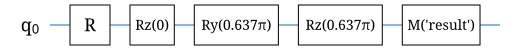

In [2]:
import cirq
from quantum_plots import draw_circuit

number_of_qubits = 1
qubits = cirq.LineQubit.range(number_of_qubits)
my_circuit = cirq.Circuit()

theta, phi, lam = 2, 2, 0 # can change theta, phi and lam

my_circuit.append(cirq.reset(qubits[0]))
# a general single-qubit rotation, set by three angles: about Z by lam, then Y by theta, then Z by phi
my_circuit.append(cirq.rz(lam).on(qubits[0]))
my_circuit.append(cirq.ry(theta).on(qubits[0]))
my_circuit.append(cirq.rz(phi).on(qubits[0]))
my_circuit.append(cirq.measure(*qubits, key='result'))

draw_circuit(my_circuit)

{'1': 7151, '0': 2849}


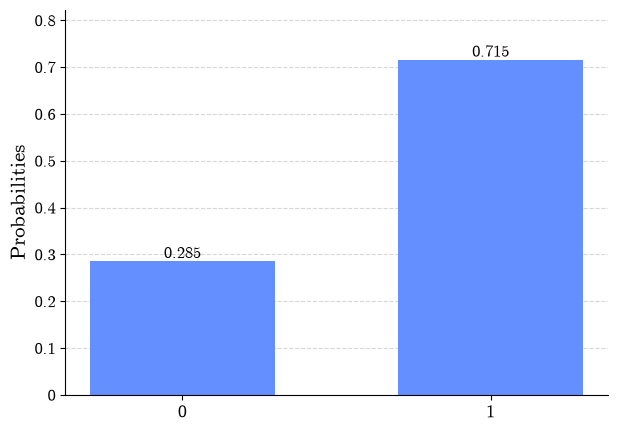

In [3]:
def bits_to_string(bits):
    return ''.join(str(b) for b in bits)

simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

from quantum_plots import plot_histogram
print(dict(counts))
plot_histogram(counts)

# First, let's define the cost. Want closer to `1`

In [4]:
def cost(given_counts):
    
    if '0' not in given_counts:
        given_counts['0'] = 0
    if '1' not in given_counts:
        given_counts['1'] = 0
    
    total_counts = given_counts['0'] + given_counts['1']

    return given_counts['0'] * 1.0 / total_counts

# Next, define a single iteration between a quantum computer and a classical computer

In [5]:
def run_once(params, print_counts = False):
    
    theta = params[0]
    phi = params[1]
    lam = params[2]
    
    my_circuit = cirq.Circuit()
    
    my_circuit.append(cirq.reset(qubits[0]))
    my_circuit.append(cirq.rz(lam).on(qubits[0]))
    my_circuit.append(cirq.ry(theta).on(qubits[0]))
    my_circuit.append(cirq.rz(phi).on(qubits[0]))
    my_circuit.append(cirq.measure(*qubits, key='result'))
    
    simulator = cirq.Simulator()
    counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)
    
    if print_counts: print(dict(counts))
    
    computed_cost = cost(counts)
    global costs
    costs.append(computed_cost)
    
    return computed_cost

In [6]:
costs = []
run_once([0,0,0])

1.0

# Finally, let a classical computer iterate over this back-and-forth

In [7]:
from scipy.optimize import minimize

def variational_loop():    
    res = minimize(run_once, [0,0,0], method='cobyla')
    return res

In [8]:
costs = []
result = variational_loop()
print(result)

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: 0.0
       x: [ 3.142e+00  1.003e+00  1.071e+00]
    nfev: 27
   maxcv: 0.0


In [9]:
run_once(result.x, print_counts = True)

{'1': 10000}


0.0

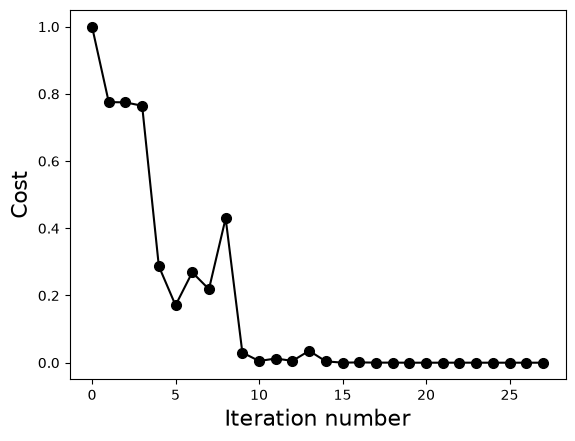

In [10]:
import matplotlib.pyplot as plotter
plotter.plot(list(range(len(costs))), costs, 'k.-', markersize=14)
plotter.xlabel('Iteration number', fontsize=16)
plotter.ylabel('Cost', fontsize=16)
plotter.show()